In [1]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/events.csv")

events = pd.read_csv(DATA_PATH)

In [2]:
events_clean = events.copy()

events_clean["datetime"] = pd.to_datetime(
    events_clean["timestamp"],
    unit="ms",
    utc=True
)

events_clean["date"] = events_clean["datetime"].dt.date

In [3]:
events_clean[["timestamp", "datetime", "date"]].head()

# %%
daily_activity = events_clean.groupby("date").agg(
    total_events=("event", "size"),
    unique_users=("visitorid", "nunique"),
    unique_items=("itemid", "nunique")
)

daily_activity.head()

,total_events,unique_users,unique_items
date,,,
2015-05-03,13683,7865,8787
2015-05-04,19414,11019,11567
2015-05-05,23015,13084,13583
2015-05-06,23920,13687,13926
2015-05-07,23164,13086,13647


In [4]:
daily_activity.describe()

,total_events,unique_users,unique_items
count,139.000000,139.000000,139.000000
mean,19828.064748,11867.151079,12030.115108
std,4170.654332,2303.606146,2059.480260
min,1528.000000,1016.000000,1204.000000
25%,16831.500000,10292.000000,10556.000000
50%,20621.000000,12348.000000,12493.000000
75%,22461.000000,13151.000000,13467.500000
max,32703.000000,17516.000000,15915.000000


In [5]:
daily_events = events_clean.pivot_table(
    index="date",
    columns="event",
    values="visitorid",
    aggfunc="count",
    fill_value=0
)

daily_events.head()

event,addtocart,transaction,view
date,,,
2015-05-03,296,83,13304
2015-05-04,579,154,18681
2015-05-05,565,225,22225
2015-05-06,647,258,23015
2015-05-07,578,217,22369


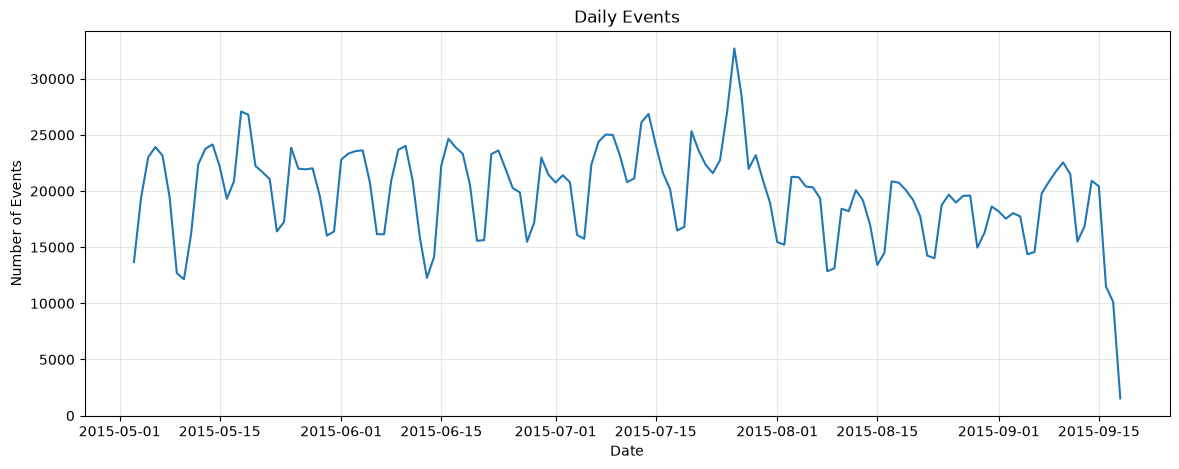

In [6]:
import matplotlib.pyplot as plt

daily_activity["total_events"].plot(
    figsize=(14, 5),
    title="Daily Events"
)

plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.grid(alpha=0.3)
plt.show()

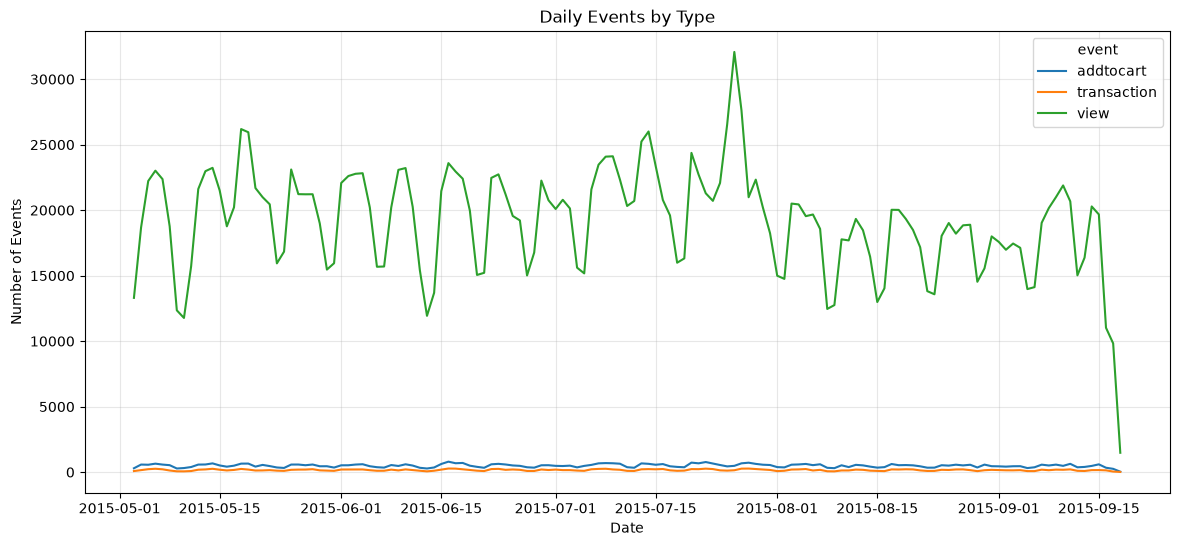

In [7]:
daily_events.plot(
    figsize=(14, 6),
    title="Daily Events by Type"
)

plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.grid(alpha=0.3)
plt.show()

In [8]:
daily_activity.nsmallest(10, "total_events")

,total_events,unique_users,unique_items
date,,,
2015-09-18,1528,1016,1204
2015-09-17,10128,6270,6973
2015-09-16,11495,6824,7723
2015-05-10,12143,7413,8030
2015-06-13,12270,7465,8221
2015-05-09,12695,7610,8199
2015-08-08,12857,8272,8485
2015-08-09,13117,8588,8778
2015-08-15,13423,8493,8904


In [9]:
daily_activity.tail(10)

,total_events,unique_users,unique_items
date,,,
2015-09-09,21761,13066,13314
2015-09-10,22548,14075,13665
2015-09-11,21517,13080,12710
2015-09-12,15496,9944,9877
2015-09-13,16859,10768,10823
2015-09-14,20913,13389,12892
2015-09-15,20427,12687,12272
2015-09-16,11495,6824,7723
2015-09-17,10128,6270,6973


In [10]:
daily_coverage = events_clean.groupby("date").agg(
    first_event=("datetime", "min"),
    last_event=("datetime", "max"),
    total_events=("event", "size")
)

daily_coverage.tail(10)

,first_event,last_event,total_events
date,,,
2015-09-09,2015-09-09 00:00:01.262+00:00,2015-09-09 23:59:48.572+00:00,21761
2015-09-10,2015-09-10 00:00:00.398+00:00,2015-09-10 23:59:54.555+00:00,22548
2015-09-11,2015-09-11 00:00:02.200+00:00,2015-09-11 23:59:51.336+00:00,21517
2015-09-12,2015-09-12 00:00:02.547+00:00,2015-09-12 23:59:47.942+00:00,15496
2015-09-13,2015-09-13 00:00:05.423+00:00,2015-09-13 23:59:56.743+00:00,16859
2015-09-14,2015-09-14 00:00:05.345+00:00,2015-09-14 23:59:45.566+00:00,20913
2015-09-15,2015-09-15 00:00:06.627+00:00,2015-09-15 23:59:58.763+00:00,20427
2015-09-16,2015-09-16 00:00:11.499+00:00,2015-09-16 23:59:58.436+00:00,11495
2015-09-17,2015-09-17 00:00:10.585+00:00,2015-09-17 23:59:55.623+00:00,10128


In [11]:
events_clean["hour"] = events_clean["datetime"].dt.hour

hourly_activity = events_clean.groupby("hour").agg(
    total_events=("event", "size"),
    unique_users=("visitorid", "nunique")
)

hourly_activity

,total_events,unique_users
hour,,
0,144303,89567
1,140702,88915
2,145879,92636
3,150860,96539
4,147184,93458
5,119572,75804
6,76972,49570
7,43944,28440
8,25309,16918


In [12]:
daily_by_event = events_clean.pivot_table(
    index="date",
    columns="event",
    values="visitorid",
    aggfunc="size",
    fill_value=0
)

from datetime import date

recent_activity = daily_by_event.loc[
    date(2015, 9, 9):date(2015, 9, 17)
]

recent_activity

event,addtocart,transaction,view
date,,,
2015-09-09,574,192,20995
2015-09-10,480,181,21887
2015-09-11,634,211,20672
2015-09-12,370,102,15024
2015-09-13,398,88,16373
2015-09-14,475,154,20284
2015-09-15,595,158,19674
2015-09-16,336,137,11022
2015-09-17,253,45,9830


In [13]:
recent_activity.pct_change() * 100

event,addtocart,transaction,view
date,,,
2015-09-09,NaN,NaN,NaN
2015-09-10,-16.376307,-5.729167,4.248631
2015-09-11,32.083333,16.574586,-5.551240
2015-09-12,-41.640379,-51.658768,-27.321981
2015-09-13,7.567568,-13.725490,8.978967
2015-09-14,19.346734,75.000000,23.886887
2015-09-15,25.263158,2.597403,-3.007296
2015-09-16,-43.529412,-13.291139,-43.976822
2015-09-17,-24.702381,-67.153285,-10.814734


In [14]:
from datetime import date


weekday_data = daily_by_event.loc[
    date(2015, 5, 4):date(2015, 9, 17)
].copy()

weekday_data["weekday"] = pd.to_datetime(
    weekday_data.index
).day_name()

weekday_summary = weekday_data.groupby("weekday")[
    ["view", "addtocart", "transaction"]
].agg(["median", "mean"])

weekday_summary

event         view               addtocart             transaction            
            median          mean    median        mean      median        mean
weekday                                                                       
Friday     19217.0  19249.789474     493.0  500.578947       153.0  153.368421
Monday     20976.5  21229.700000     570.5  568.550000       195.0  192.400000
Saturday   15024.0  15602.894737     370.0  365.736842        98.0   95.315789
Sunday     15557.0  16398.736842     356.0  381.631579        97.0  100.631579
Thursday   20743.5  20203.000000     543.0  547.550000       206.0  187.500000
Tuesday    21416.5  21575.950000     579.0  579.250000       198.5  198.650000
Wednesday  21250.0  20778.950000     576.5  569.200000       206.5  207.550000

In [15]:
weekday_median = weekday_data.groupby("weekday")[
    ["view", "addtocart", "transaction"]
].median()

for target_date in [date(2015, 9, 16), date(2015, 9, 17)]:
    weekday = pd.Timestamp(target_date).day_name()

    print(f"\n{target_date} ({weekday})")

    comparison = pd.DataFrame({
        "actual": weekday_data.loc[target_date, [
            "view", "addtocart", "transaction"
        ]],
        "weekday_median": weekday_median.loc[weekday]
    })

    comparison["deviation_%"] = (
        comparison["actual"] / comparison["weekday_median"] - 1
    ) * 100

    print(comparison.round(2))


2015-09-16 (Wednesday)
             actual  weekday_median  deviation_%
event                                           
view          11022         21250.0       -48.13
addtocart       336           576.5       -41.72
transaction     137           206.5       -33.66

2015-09-17 (Thursday)
             actual  weekday_median  deviation_%
event                                           
view           9830         20743.5       -52.61
addtocart       253           543.0       -53.41
transaction      45           206.0       -78.16


In [16]:
daily_event_metrics = (
    events_clean.groupby(["date", "event"])
    .agg(
        event_rows=("event", "size"),
        unique_users=("visitorid", "nunique"),
        unique_transactions=("transactionid", "nunique")
    )
    .reset_index()
)

daily_event_metrics[
    daily_event_metrics["date"].between(
        date(2015, 9, 9),
        date(2015, 9, 17)
    )
]

,date,event,event_rows,unique_users,unique_transactions
387,2015-09-09,addtocart,574,348,0
388,2015-09-09,transaction,192,120,159
389,2015-09-09,view,20995,13026,0
390,2015-09-10,addtocart,480,322,0
391,2015-09-10,transaction,181,108,138
392,2015-09-10,view,21887,14030,0
393,2015-09-11,addtocart,634,348,0
394,2015-09-11,transaction,211,106,140
395,2015-09-11,view,20672,13025,0
396,2015-09-12,addtocart,370,250,0


In [17]:
user_activity = events.groupby("visitorid").agg(
    total_events=("event", "size"),
    unique_items=("itemid", "nunique"),
    first_seen=("timestamp", "min"),
    last_seen=("timestamp", "max")
)

In [18]:
user_activity["total_events"].value_counts().sort_index().head(20)

total_events
1     1001560
2      205992
3       79612
4       38796
5       22967
6       14178
7        9482
8        6812
9        4940
10       3659
11       2831
12       2217
13       1822
14       1511
15       1269
16       1059
17        853
18        765
19        645
20        553
Name: count, dtype: int64

In [19]:
user_activity["total_events"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

0.500     1.0
0.750     2.0
0.900     3.0
0.950     5.0
0.990    13.0
0.999    47.0
Name: total_events, dtype: float64

In [20]:
one_event_share = (
    user_activity["total_events"].eq(1).mean() * 100
)

print(f"Доля пользователей с одним событием: {one_event_share:.2f}%")

Доля пользователей с одним событием: 71.15%


In [21]:
one_two_events_share = (
    user_activity["total_events"].le(2).mean() * 100
)

print(f"Доля пользователей с 1–2 событиями: {one_two_events_share:.2f}%")

Доля пользователей с 1–2 событиями: 85.79%


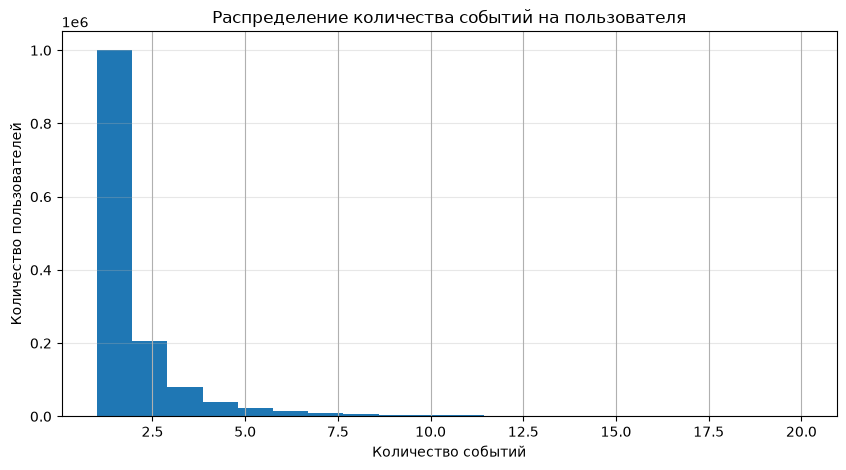

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

user_activity.loc[
    user_activity["total_events"] <= 20,
    "total_events"
].hist(bins=20)

plt.title("Распределение количества событий на пользователя")
plt.xlabel("Количество событий")
plt.ylabel("Количество пользователей")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [23]:
user_event_matrix = (
    events_clean
    .assign(value=1)
    .pivot_table(
        index="visitorid",
        columns="event",
        values="value",
        aggfunc="max",
        fill_value=0
    )
)

user_event_matrix.sum()

event
addtocart        37722
transaction      11719
view           1404179
dtype: int64

In [24]:
total_users = events_clean["visitorid"].nunique()

event_user_share = (
    user_event_matrix.sum()
    .div(total_users)
    .mul(100)
    .sort_values(ascending=False)
)

print(event_user_share.round(2))

event
view           99.76
addtocart       2.68
transaction     0.83
dtype: float64


In [25]:
view_users = user_event_matrix["view"].eq(1)
cart_users = user_event_matrix["addtocart"].eq(1)
purchase_users = user_event_matrix["transaction"].eq(1)

segments = {
    "Только просмотр": view_users & ~cart_users & ~purchase_users,
    "Просмотр + корзина, без покупки": view_users & cart_users & ~purchase_users,
    "Все три события": view_users & cart_users & purchase_users,
    "Корзина + покупка, без просмотра": ~view_users & cart_users & purchase_users,
    "Покупка без просмотра и корзины": ~view_users & ~cart_users & purchase_users,
    "Просмотр + покупка, без корзины": view_users & ~cart_users & purchase_users,
    "Только корзина": ~view_users & cart_users & ~purchase_users,
}

segment_counts = pd.Series({
    name: mask.sum()
    for name, mask in segments.items()
}).sort_values(ascending=False)

print(segment_counts)

Только просмотр                     1368715
Просмотр + корзина, без покупки       24173
Все три события                       10228
Только корзина                         2973
Просмотр + покупка, без корзины        1063
Корзина + покупка, без просмотра        348
Покупка без просмотра и корзины          80
dtype: int64


In [26]:
view_to_cart = (
    user_event_matrix["addtocart"].sum()
    / user_event_matrix["view"].sum()
    * 100
)

cart_to_purchase = (
    (
        user_event_matrix["addtocart"].eq(1)
        & user_event_matrix["transaction"].eq(1)
    ).sum()
    / user_event_matrix["addtocart"].sum()
    * 100
)

view_to_purchase = (
    (
        user_event_matrix["view"].eq(1)
        & user_event_matrix["transaction"].eq(1)
    ).sum()
    / user_event_matrix["view"].sum()
    * 100
)

print(f"View → Add to cart: {view_to_cart:.2f}%")
print(f"Add to cart → Purchase: {cart_to_purchase:.2f}%")
print(f"View → Purchase: {view_to_purchase:.2f}%")

View → Add to cart: 2.69%
Add to cart → Purchase: 28.04%
View → Purchase: 0.80%


In [28]:
top_items = (
    events_clean
    .groupby(["event", "itemid"])
    .agg(
        event_count=("itemid", "size"),
        unique_users=("visitorid", "nunique")
    )
    .reset_index()
)

top_views = (
    top_items[top_items["event"] == "view"]
    .sort_values("event_count", ascending=False)
    .head(10)
)

top_carts = (
    top_items[top_items["event"] == "addtocart"]
    .sort_values("event_count", ascending=False)
    .head(10)
)

top_purchases = (
    top_items[top_items["event"] == "transaction"]
    .sort_values("event_count", ascending=False)
    .head(10)
)
display(top_views)
display(top_carts)
display(top_purchases)

,event,itemid,event_count,unique_users
130546,view,187946,3410,2911
268205,view,461686,2539,1379
38645,view,5411,2325,2078
222463,view,370653,1854,1577
146349,view,219512,1740,1358
185928,view,298009,1642,1342
84893,view,96924,1633,1359
191793,view,309778,1565,1053
165300,view,257040,1531,979
229346,view,384302,1528,1143


,event,itemid,event_count,unique_users
23635,addtocart,461686,306,267
15963,addtocart,312728,162,129
21014,addtocart,409804,156,128
16318,addtocart,320130,141,131
1439,addtocart,29196,136,101
390,addtocart,7943,97,87
2384,addtocart,48030,95,85
22637,addtocart,441852,90,82
22839,addtocart,445351,89,80
13088,addtocart,257040,89,79


,event,itemid,event_count,unique_users
35801,transaction,461686,133,129
26958,transaction,119736,97,42
29339,transaction,213834,92,80
31967,transaction,312728,46,37
24088,transaction,7943,46,46
35387,transaction,445351,45,42
25093,transaction,48030,41,38
34768,transaction,420960,38,36
30292,transaction,248455,38,31
24328,transaction,17478,37,35


In [32]:
item_comparison = (
    top_items
    .pivot(
        index="itemid",
        columns="event",
        values=["event_count", "unique_users"]
    )
    .fillna(0)
)

item_comparison.columns = [
    f"{metric}_{event}"
    for metric, event in item_comparison.columns
]

item_comparison = item_comparison.reset_index()

item_comparison.head()



,itemid,event_count_addtocart,event_count_transaction,event_count_view,unique_users_addtocart,unique_users_transaction,unique_users_view
0,3,0.0,0.0,2.0,0.0,0.0,2.0
1,4,0.0,0.0,3.0,0.0,0.0,3.0
2,6,0.0,0.0,29.0,0.0,0.0,26.0
3,9,0.0,0.0,2.0,0.0,0.0,2.0
4,15,3.0,1.0,18.0,2.0,1.0,13.0


In [ ]:
item_comparison[
    item_comparison["itemid"] == 461686
]

,itemid,event_count_addtocart,event_count_transaction,event_count_view,unique_users_addtocart,unique_users_transaction,unique_users_view
232496,461686,306.0,133.0,2539.0,267.0,129.0,1379.0


In [33]:
top_items_by_buyers = (
    item_comparison
    .sort_values("unique_users_transaction", ascending=False)
    .head(10)
)

display(top_items_by_buyers)

,itemid,event_count_addtocart,event_count_transaction,event_count_view,unique_users_addtocart,unique_users_transaction,unique_users_view
232496,461686,306.0,133.0,2539.0,267.0,129.0,1379.0
107690,213834,17.0,92.0,293.0,17.0,80.0,199.0
3980,7943,97.0,46.0,1346.0,87.0,46.0,843.0
60527,119736,44.0,97.0,752.0,30.0,42.0,251.0
224330,445351,89.0,45.0,939.0,80.0,42.0,618.0
24339,48030,95.0,41.0,986.0,85.0,38.0,628.0
157492,312728,162.0,46.0,947.0,129.0,37.0,602.0
212061,420960,60.0,38.0,796.0,55.0,36.0,371.0
8763,17478,72.0,37.0,631.0,65.0,35.0,378.0
209597,416017,49.0,32.0,393.0,45.0,32.0,186.0


In [35]:
import numpy as np

item_comparison["buyer_viewer_ratio"] = (
    item_comparison["unique_users_transaction"]
    / item_comparison["unique_users_view"].replace(0, np.nan)
    * 100
)

top_item_ratios = (
    item_comparison
    .dropna(subset=["buyer_viewer_ratio"])
    .query("unique_users_view >= 100")
    .sort_values("buyer_viewer_ratio", ascending=False)
    .head(10)
)

display(top_item_ratios)

,itemid,event_count_addtocart,event_count_transaction,event_count_view,unique_users_addtocart,unique_users_transaction,unique_users_view,buyer_viewer_ratio
107690,213834,17.0,92.0,293.0,17.0,80.0,199.0,40.201005
168412,334401,8.0,28.0,200.0,7.0,24.0,130.0,18.461538
209597,416017,49.0,32.0,393.0,45.0,32.0,186.0,17.204301
60527,119736,44.0,97.0,752.0,30.0,42.0,251.0,16.733068
109584,217605,23.0,19.0,232.0,22.0,19.0,140.0,13.571429
46766,92466,30.0,16.0,181.0,28.0,16.0,124.0,12.903226
40924,80858,25.0,12.0,177.0,24.0,12.0,105.0,11.428571
145385,288525,20.0,16.0,178.0,15.0,16.0,149.0,10.738255
87904,174489,24.0,13.0,146.0,21.0,11.0,103.0,10.679612
125146,248455,52.0,38.0,575.0,41.0,31.0,291.0,10.652921


In [38]:
item_comparison["cart_viewer_ratio"] = (
    item_comparison["unique_users_addtocart"]
    / item_comparison["unique_users_view"].replace(0, np.nan)
    * 100
)

item_comparison["purchase_cart_user_ratio"] = (
    item_comparison["unique_users_transaction"]
    / item_comparison["unique_users_addtocart"].replace(0, np.nan)
    * 100
)

display(
    item_comparison
    .query("unique_users_view >= 100")
    .sort_values("unique_users_view", ascending=False)
    .head(15)
)
display(
    item_comparison
    .query(
        "unique_users_addtocart >= 20 "
        "and unique_users_view >= 100"
    )
    .sort_values("purchase_cart_user_ratio")
    .head(10)
)

,itemid,event_count_addtocart,event_count_transaction,event_count_view,unique_users_addtocart,unique_users_transaction,unique_users_view,buyer_viewer_ratio,cart_viewer_ratio,purchase_cart_user_ratio
94720,187946,2.0,0.0,3410.0,2.0,0.0,2911.0,0.000000,0.068705,0.000000
2719,5411,9.0,0.0,2325.0,9.0,0.0,2078.0,0.000000,0.433109,0.000000
186716,370653,0.0,0.0,1854.0,0.0,0.0,1577.0,0.000000,0.000000,NaN
232496,461686,306.0,133.0,2539.0,267.0,129.0,1379.0,9.354605,19.361856,48.314607
49024,96924,0.0,0.0,1633.0,0.0,0.0,1359.0,0.000000,0.000000,NaN
110536,219512,48.0,12.0,1740.0,47.0,12.0,1358.0,0.883652,3.460972,25.531915
150148,298009,0.0,0.0,1642.0,0.0,0.0,1342.0,0.000000,0.000000,NaN
169261,335975,0.0,0.0,1428.0,0.0,0.0,1154.0,0.000000,0.000000,NaN
193605,384302,65.0,15.0,1528.0,55.0,14.0,1143.0,1.224847,4.811899,25.454545
76432,151444,0.0,0.0,1230.0,0.0,0.0,1103.0,0.000000,0.000000,NaN


,itemid,event_count_addtocart,event_count_transaction,event_count_view,unique_users_addtocart,unique_users_transaction,unique_users_view,buyer_viewer_ratio,cart_viewer_ratio,purchase_cart_user_ratio
178513,354233,24.0,1.0,983.0,21.0,1.0,847.0,0.118064,2.479339,4.761905
227537,451806,23.0,2.0,294.0,21.0,2.0,238.0,0.840336,8.823529,9.523810
200751,398579,25.0,3.0,355.0,20.0,2.0,216.0,0.925926,9.259259,10.000000
162093,321905,20.0,2.0,442.0,20.0,2.0,356.0,0.561798,5.617978,10.000000
225475,447661,45.0,5.0,575.0,38.0,4.0,451.0,0.886918,8.425721,10.526316
140791,279457,63.0,7.0,435.0,62.0,7.0,358.0,1.955307,17.318436,11.290323
144852,287449,46.0,4.0,271.0,35.0,4.0,160.0,2.500000,21.875000,11.428571
173653,344723,32.0,4.0,451.0,25.0,3.0,305.0,0.983607,8.196721,12.000000
177142,351481,28.0,3.0,343.0,24.0,3.0,251.0,1.195219,9.561753,12.500000
91226,181045,24.0,3.0,173.0,24.0,3.0,127.0,2.362205,18.897638,12.500000


In [39]:
reliable_items = (
    item_comparison
    .query(
        "unique_users_view >= 100 "
        "and unique_users_addtocart >= 20"
    )
    .copy()
)

reliable_items = reliable_items.sort_values(
    "purchase_cart_user_ratio"
)

display(
    reliable_items[
        [
            "itemid",
            "unique_users_view",
            "unique_users_addtocart",
            "unique_users_transaction",
            "cart_viewer_ratio",
            "purchase_cart_user_ratio"
        ]
    ].head(15)
)

,itemid,unique_users_view,unique_users_addtocart,unique_users_transaction,cart_viewer_ratio,purchase_cart_user_ratio
178513,354233,847.0,21.0,1.0,2.479339,4.761905
227537,451806,238.0,21.0,2.0,8.823529,9.523810
200751,398579,216.0,20.0,2.0,9.259259,10.000000
162093,321905,356.0,20.0,2.0,5.617978,10.000000
225475,447661,451.0,38.0,4.0,8.425721,10.526316
140791,279457,358.0,62.0,7.0,17.318436,11.290323
144852,287449,160.0,35.0,4.0,21.875000,11.428571
173653,344723,305.0,25.0,3.0,8.196721,12.000000
177142,351481,251.0,24.0,3.0,9.561753,12.500000
91226,181045,127.0,24.0,3.0,18.897638,12.500000


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "reports").exists() and (PROJECT_ROOT.parent / "reports").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Папка для графиков:", FIGURES_DIR)

Папка для графиков: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/figures


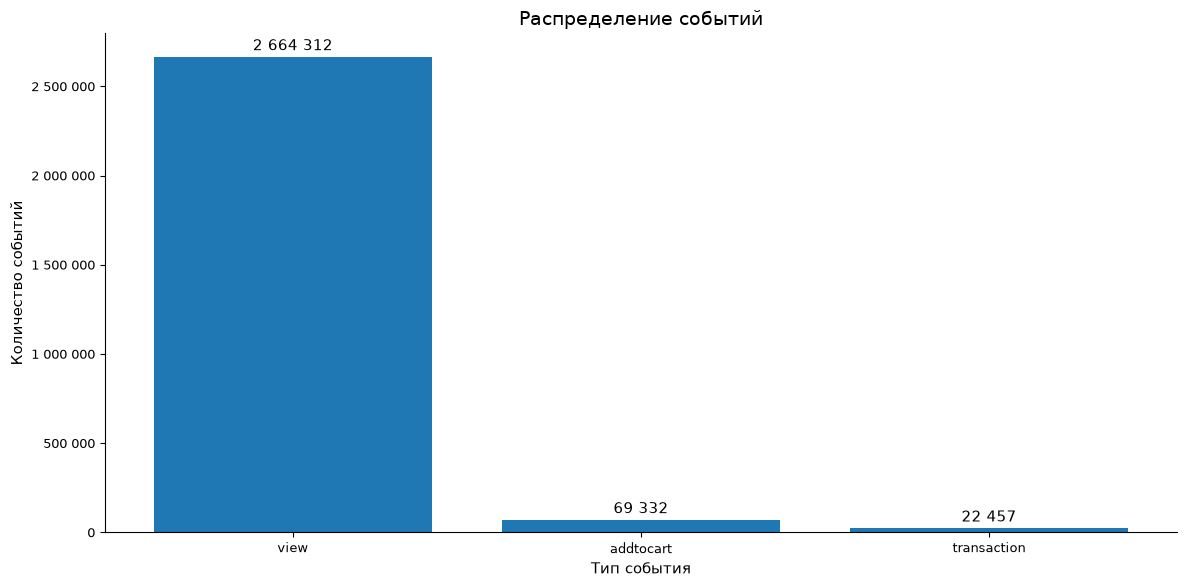

In [ ]:
event_counts = events_clean["event"].value_counts()

fig, ax = plt.subplots()

event_order = ["view", "addtocart", "transaction"]
event_counts = event_counts.reindex(event_order)

bars = ax.bar(
    event_counts.index,
    event_counts.values
)

ax.set_title("Распределение событий")
ax.set_xlabel("Тип события")
ax.set_ylabel("Количество событий")
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:,.0f}".replace(",", " "),
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_event_distribution.png", bbox_inches="tight")
plt.show()

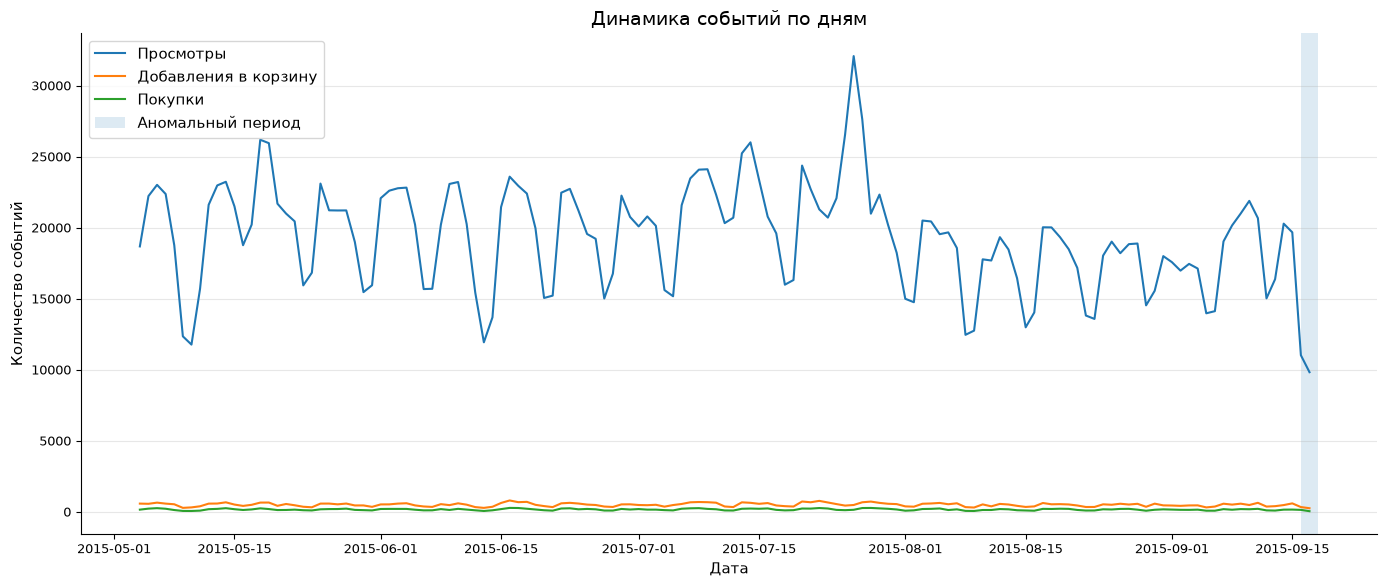

In [42]:
daily_plot = events_clean.groupby("date").agg(
    views=("event", lambda x: (x == "view").sum()),
    addtocart=("event", lambda x: (x == "addtocart").sum()),
    transactions=("event", lambda x: (x == "transaction").sum())
)

daily_plot.index = pd.to_datetime(daily_plot.index)

# Исключаем неполные первый и последний дни
daily_plot = daily_plot.loc["2015-05-04":"2015-09-17"]

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(daily_plot.index, daily_plot["views"], label="Просмотры")
ax.plot(daily_plot.index, daily_plot["addtocart"], label="Добавления в корзину")
ax.plot(daily_plot.index, daily_plot["transactions"], label="Покупки")

# Отмечаем аномальный период
ax.axvspan(
    pd.Timestamp("2015-09-16"),
    pd.Timestamp("2015-09-18"),
    alpha=0.15,
    label="Аномальный период"
)

ax.set_title("Динамика событий по дням")
ax.set_xlabel("Дата")
ax.set_ylabel("Количество событий")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_daily_activity.png", bbox_inches="tight")
plt.show()

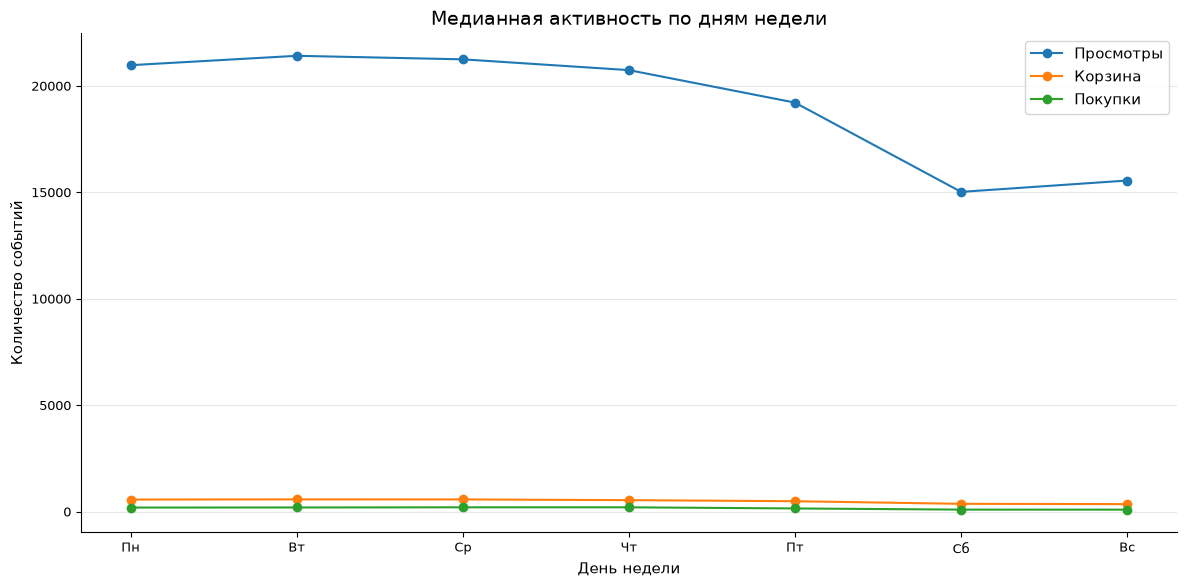

In [ ]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_data = daily_plot.copy()
weekday_data["weekday"] = weekday_data.index.day_name()

weekday_summary = (
    weekday_data.groupby("weekday")[
        ["views", "addtocart", "transactions"]
    ]
    .median()
    .reindex(weekday_order)
)

weekday_names_ru = [
    "Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(weekday_names_ru, weekday_summary["views"], marker="o", label="Просмотры")
ax.plot(weekday_names_ru, weekday_summary["addtocart"], marker="o", label="Корзина")
ax.plot(weekday_names_ru, weekday_summary["transactions"], marker="o", label="Покупки")

ax.set_title("Медианная активность по дням недели")
ax.set_xlabel("День недели")
ax.set_ylabel("Количество событий")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_weekday_activity.png", bbox_inches="tight")
plt.show()

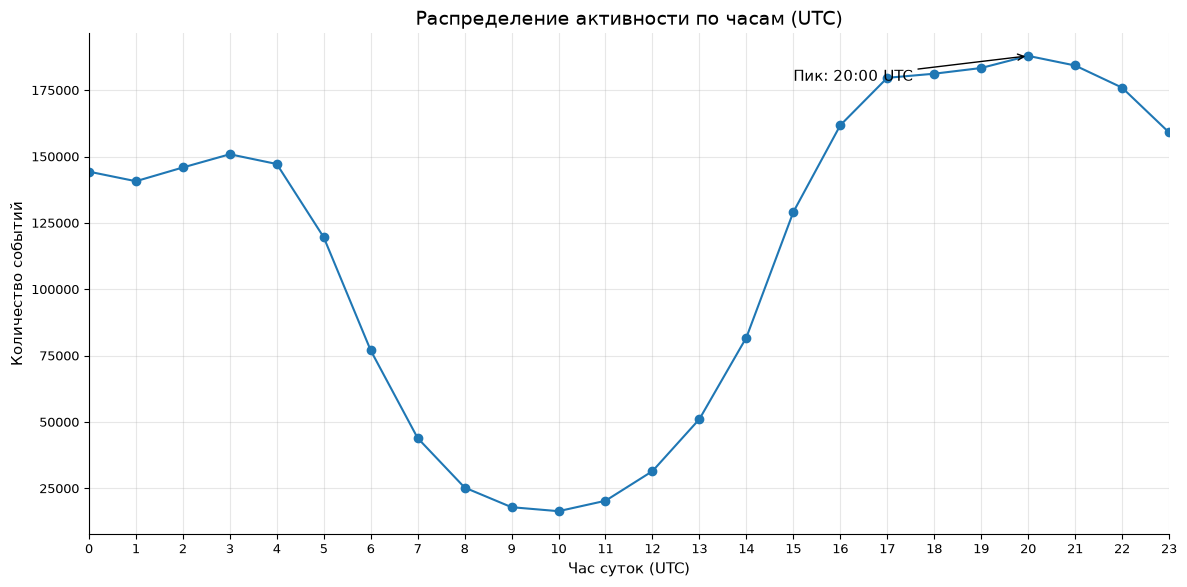

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

hourly_plot = hourly_activity.sort_index()

ax.plot(
    hourly_plot.index,
    hourly_plot["total_events"],
    marker="o",
    label="Все события"
)

ax.set_title("Распределение активности по часам (UTC)")
ax.set_xlabel("Час суток (UTC)")
ax.set_ylabel("Количество событий")
ax.set_xticks(range(24))
ax.set_xlim(0, 23)
ax.grid(alpha=0.3)

# Выделяем час с максимальной активностью
peak_hour = hourly_plot["total_events"].idxmax()
peak_value = hourly_plot["total_events"].max()

ax.annotate(
    f"Пик: {peak_hour}:00 UTC",
    xy=(peak_hour, peak_value),
    xytext=(peak_hour - 5, peak_value * 0.95),
    arrowprops={"arrowstyle": "->"}
)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "02_hourly_activity.png",
    bbox_inches="tight"
)
plt.show()

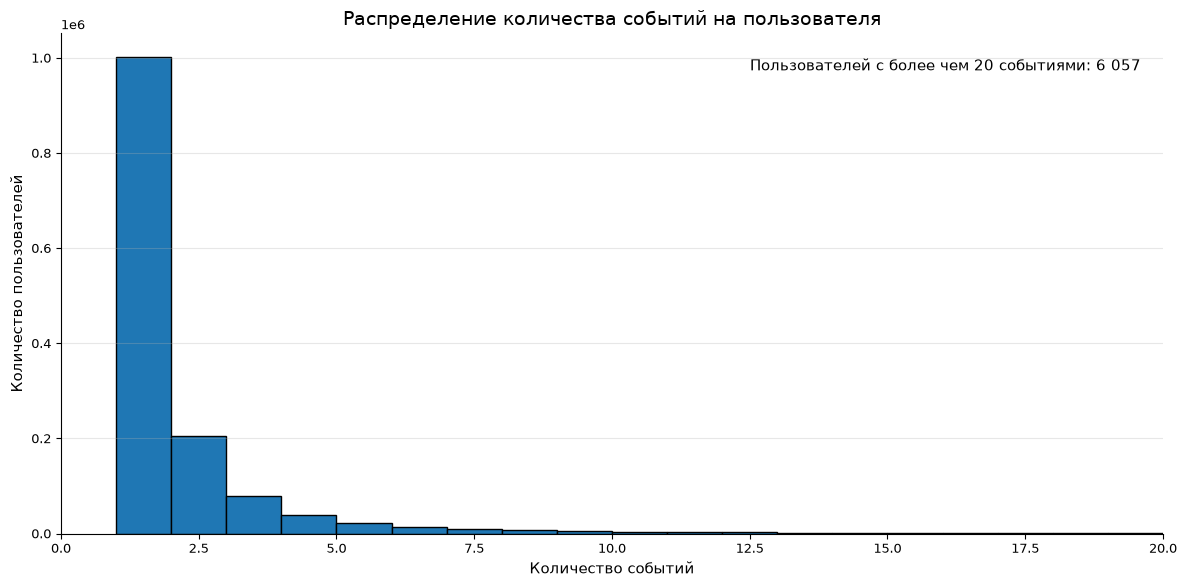

In [ ]:
fig, ax = plt.subplots()

activity_counts = user_activity["total_events"]

ax.hist(
    activity_counts,
    bins=range(1, 22),
    edgecolor="black"
)

ax.set_title("Распределение количества событий на пользователя")
ax.set_xlabel("Количество событий")
ax.set_ylabel("Количество пользователей")
ax.set_xlim(0, 20)

ax.text(
    0.98, 0.95,
    f"Пользователей с более чем 20 событиями: "
    f"{(activity_counts > 20).sum():,}".replace(",", " "),
    transform=ax.transAxes,
    ha="right",
    va="top"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_user_activity_distribution.png", bbox_inches="tight")
plt.show()

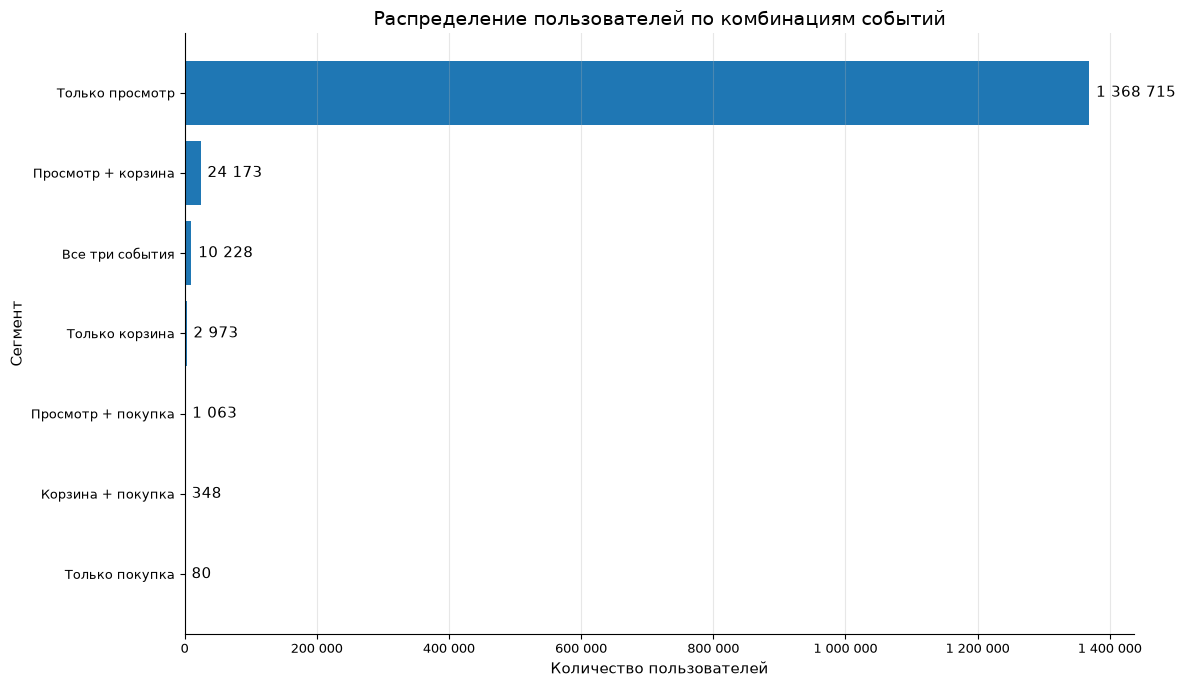

In [ ]:
segment_counts = {
    "Только просмотр": (
        user_event_matrix["view"].eq(1)
        & user_event_matrix["addtocart"].eq(0)
        & user_event_matrix["transaction"].eq(0)
    ).sum(),

    "Просмотр + корзина": (
        user_event_matrix["view"].eq(1)
        & user_event_matrix["addtocart"].eq(1)
        & user_event_matrix["transaction"].eq(0)
    ).sum(),

    "Все три события": (
        user_event_matrix["view"].eq(1)
        & user_event_matrix["addtocart"].eq(1)
        & user_event_matrix["transaction"].eq(1)
    ).sum(),

    "Только корзина": (
        user_event_matrix["view"].eq(0)
        & user_event_matrix["addtocart"].eq(1)
        & user_event_matrix["transaction"].eq(0)
    ).sum(),

    "Просмотр + покупка": (
        user_event_matrix["view"].eq(1)
        & user_event_matrix["addtocart"].eq(0)
        & user_event_matrix["transaction"].eq(1)
    ).sum(),

    "Корзина + покупка": (
        user_event_matrix["view"].eq(0)
        & user_event_matrix["addtocart"].eq(1)
        & user_event_matrix["transaction"].eq(1)
    ).sum(),

    "Только покупка": (
        user_event_matrix["view"].eq(0)
        & user_event_matrix["addtocart"].eq(0)
        & user_event_matrix["transaction"].eq(1)
    ).sum()
}

segment_series = pd.Series(segment_counts).sort_values()

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(segment_series.index, segment_series.values)

ax.set_title("Распределение пользователей по комбинациям событий")
ax.set_xlabel("Количество пользователей")
ax.set_ylabel("Сегмент")

ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
)

for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:,.0f}".replace(",", " "),
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_user_event_segments.png", bbox_inches="tight")
plt.show()

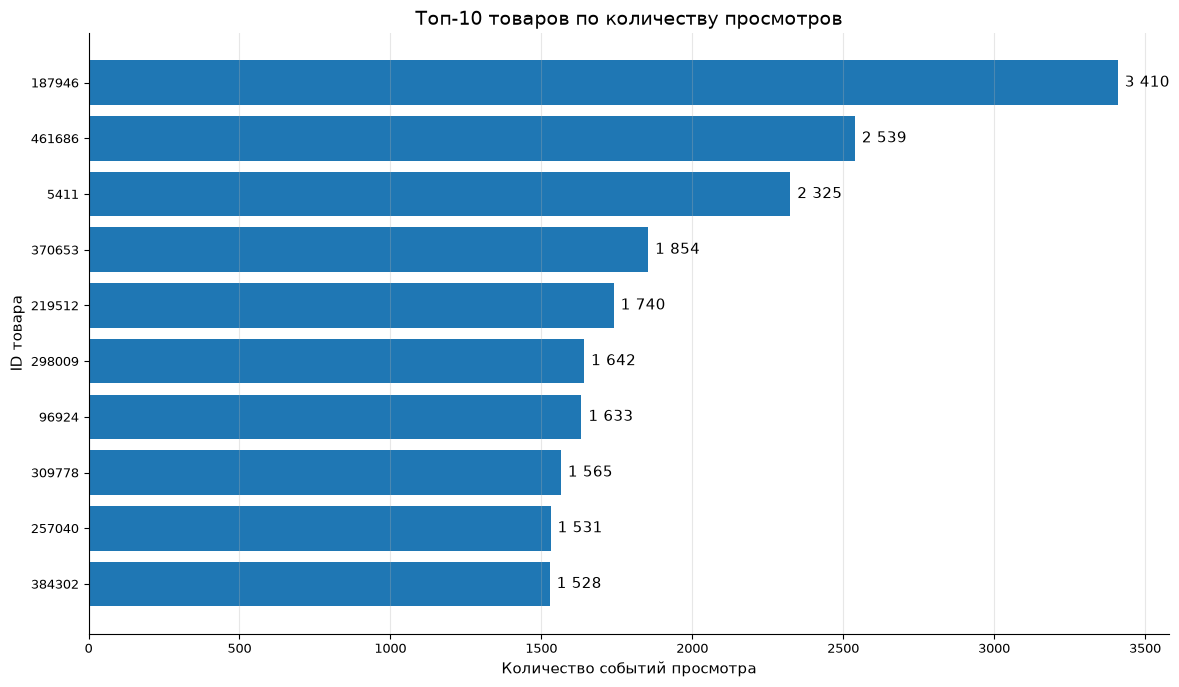

In [ ]:
top_views = (
    top_items[top_items["event"] == "view"]
    .nlargest(10, "event_count")
    .sort_values("event_count")
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_views["itemid"].astype(str),
    top_views["event_count"]
)

ax.set_title("Топ-10 товаров по количеству просмотров")
ax.set_xlabel("Количество событий просмотра")
ax.set_ylabel("ID товара")

for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:,.0f}".replace(",", " "),
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_top_viewed_items.png", bbox_inches="tight")
plt.show()

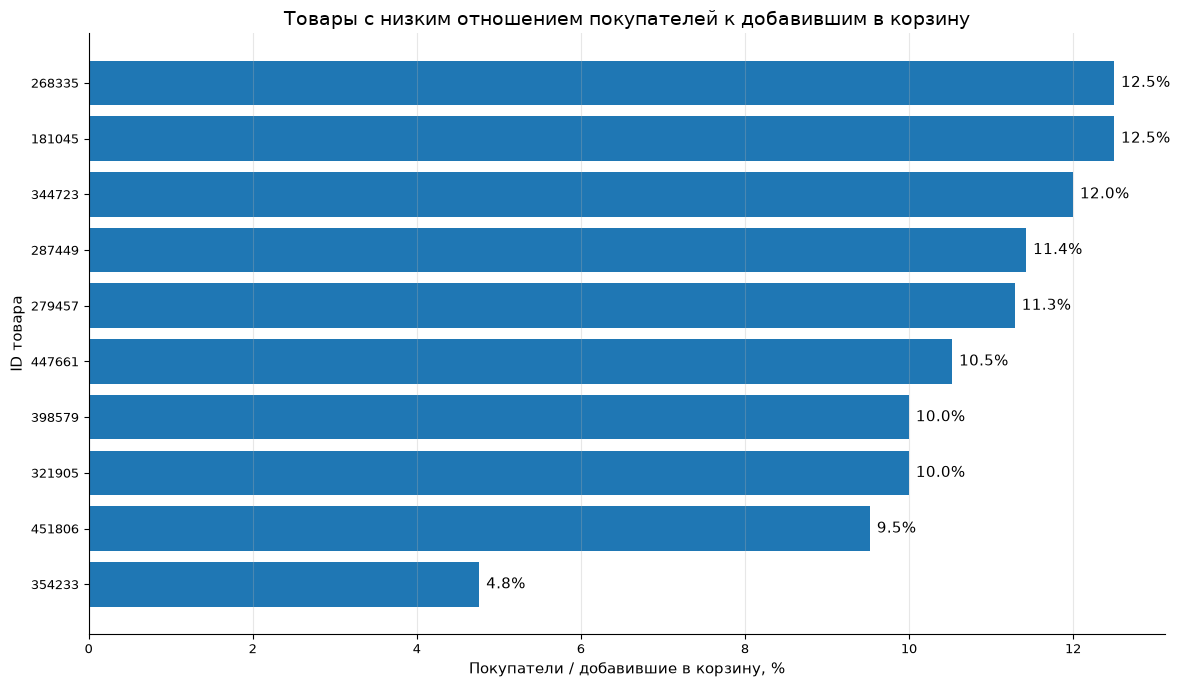

In [ ]:
low_purchase_items = item_comparison[
    (item_comparison["unique_users_view"] >= 100)
    & (item_comparison["unique_users_addtocart"] >= 20)
].copy()

low_purchase_items = (
    low_purchase_items
    .nsmallest(10, "purchase_cart_user_ratio")
    .sort_values("purchase_cart_user_ratio", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    low_purchase_items["itemid"].astype(str),
    low_purchase_items["purchase_cart_user_ratio"]
)

ax.set_title("Товары с низким отношением покупателей к добавившим в корзину")
ax.set_xlabel("Покупатели / добавившие в корзину, %")
ax.set_ylabel("ID товара")

for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:.1f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_low_purchase_cart_ratio.png", bbox_inches="tight")
plt.show()